# Week 1 — Run it, then discover a real truth yourself

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ShayanAhmed12/flyrank-internship-ml/blob/main/notebooks/01_first_look_and_discovery.ipynb?flush_cache=true)

By the end of this notebook you will have:
1. **Run a real ML pipeline** on real (anonymized) search data and watched a learned model beat a hand-written rule.
2. **Rediscovered a real finding yourself** in ~10 lines of pandas.

No prior ML needed. Everything runs on the small anonymized dataset that ships with this repo — no credentials, no private data.

## 0. Setup (Colab or local)
On Colab this clones the repo and installs requirements. Locally it just moves to the repo root.

In [1]:
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/flyrank-bih/flyrank-ml-internship-starter"
REPO_DIR = "flyrank-ml-internship-starter"

if IN_COLAB:
    if not os.path.isdir(REPO_DIR):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
else:
    # find the repo root from wherever this kernel started
    while not os.path.isdir("data/raw") and os.getcwd() != "/":
        os.chdir("..")

print("Working dir:", os.getcwd())
assert os.path.exists("data/raw/content_refresh_anonymized.csv"), "starter CSV not found — are you at the repo root?"
print("Starter data found. You're ready.")

Working dir: <repo>
Starter data found. You're ready.


## 1. Run the whole pipeline

This runs `scripts/run_all.py`: prepare features → baseline rule → train 3 models → evaluate → PDF.
It takes ~1 minute on the 30,000-row sample.

In [2]:
# Watch it work — each of the 5 steps prints live as it runs (~1 minute total).
!{sys.executable} scripts/run_all.py



▶ Step 1/5 — Prepare features — clean the data, build the feature vector, define the label
Prepared 30,000 rows from 30,000 raw rows
Wrote data\processed\refresh_feature_vector.csv

▶ Step 2/5 — Baseline — a transparent hand-written rule to beat
Wrote baseline queue: data\processed\baseline_refresh_queue.csv
Top-50 declining rate (full data, not the evaluated holdout Precision@50): 0.340

▶ Step 3/5 — Train — logistic regression, decision tree, random forest (client-holdout split)
Trained 3 models on 30,000 rows
Split strategy: client_holdout
Best model: random_forest
Wrote predictions: data\processed\model_predictions.csv
Wrote model results: outputs\model_results.json

▶ Step 4/5 — Evaluate — ranked refresh queue, charts, and the Markdown report
Wrote final refresh queue: outputs\refresh_queue.csv
Wrote model report: outputs\model_report.md
Wrote charts in: outputs\charts

▶ Step 5/5 — Report — a shareable PDF summary
Wrote PDF report: outputs\flyrank_refresh_model_results.pdf

Pipe

### What just happened?
The pipeline ranked every page for "refresh review" two ways: a **hand-written rule baseline** and a **learned model**. Let's compare them on **Precision@50** — of the top 50 pages each says to fix first, how many are actually declining?

In [3]:
import json
res = json.load(open("outputs/model_results.json"))

base = res["baseline"]["baseline_precision_at_50"]
rf   = res["models"]["random_forest"]["precision_at_50"]

print(f"Hand-written rule  Precision@50: {base:.3f}   (~{round(base*50)} of the top 50 right)")
print(f"Random forest      Precision@50: {rf:.3f}   (~{round(rf*50)} of the top 50 right)")
print(f"\nThe learned model roughly {rf/base:.1f}x the rule on this metric.")
print("Validation split used:", res["split_strategy"], "(pages from a client are never in both train and test)")

Hand-written rule  Precision@50: 0.240   (~12 of the top 50 right)
Random forest      Precision@50: 0.680   (~34 of the top 50 right)

The learned model roughly 2.8x the rule on this metric.
Validation split used: client_holdout (pages from a client are never in both train and test)


You just ran a real ML system on real search data and saw a learned ranking beat a fixed rule. Now open `outputs/model_report.md` and skim it — that Markdown report is the *shape* of what your own capstone should produce.

## 2. Discover a real truth yourself

The safest, most satisfying early wins are **things you find in the data** — un-leakable, and they *are* the core lesson. Run the three cells below. Each is ~10 lines of pandas and each overturns a common SEO belief.

Every number is **computed live from the shipped CSV** — nothing is hardcoded.

In [4]:
import pandas as pd, numpy as np
df = pd.read_csv("data/raw/content_refresh_anonymized.csv")
print(df.shape[0], "rows,", df.shape[1], "columns")
df.head(3)

30000 rows, 44 columns


,content_id,client_id,search_volume,competition,competition_level,cpc,content_type,main_intent,word_count,char_count,...,char_count_tier,ctr,avg_position,engagement_rate,scroll_rate,ai_traffic_pct,impression_tier,position_tier,trend_direction,trend_pct
0,content_304f48230142,client_f369cb89fc,10.0,0.67,HIGH,2.05,keyword article,transactional,3221.0,20457.0,...,15000-25000,0.76,10.6,5.88,4.55,0.0,good,striking,down,-41.4
1,content_a1fb4e703a9e,client_4e07408562,90.0,0.01,LOW,0.05,keyword article,informational,2481.0,15562.0,...,15000-25000,0.05,20.3,0.00,10.00,0.0,good,page_3_5,down,-57.7
2,content_9aa793d4d895,client_7f2253d7e2,0.0,0.00,LOW,0.00,keyword article,informational,3515.0,23643.0,...,15000-25000,0.09,36.5,0.00,28.57,0.0,good,page_3_5,down,-60.9


### Discovery A — "High search volume means more traffic." Does it?

In [5]:
corr = df["search_volume"].corr(df["impressions_90d"])
print(f"Correlation between search_volume and impressions_90d: {corr:.3f}")
print("Near zero -> keyword search volume barely predicts the traffic a page actually gets.")

Correlation between search_volume and impressions_90d: 0.001
Near zero -> keyword search volume barely predicts the traffic a page actually gets.


### Discovery B — the CTR cliff by position
Click-through rate is not flat: it collapses as you move down the results.

position_tier
page_1      0.3548
top_3       0.3341
striking    0.2558
page_3_5    0.1424
deep        0.0554


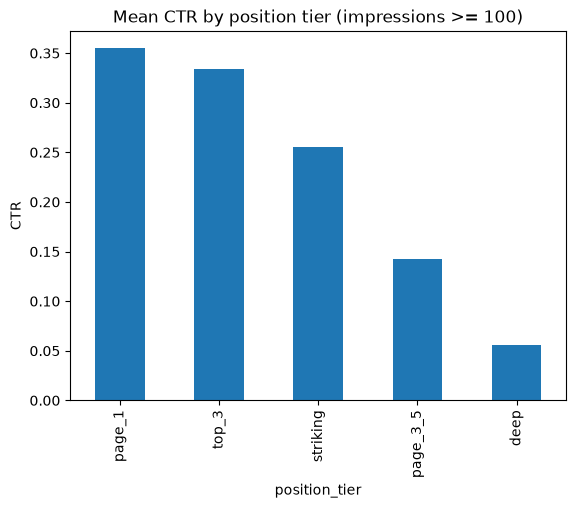

In [6]:
visible = df[df["impressions_90d"] >= 100]
ctr_by_pos = visible.groupby("position_tier")["ctr"].mean().sort_values(ascending=False)
print(ctr_by_pos.round(4).to_string())
ctr_by_pos.plot(kind="bar", title="Mean CTR by position tier (impressions >= 100)", ylabel="CTR");

### Discovery C — is longer content the lever?
Compare word count for **declining** vs **growing** pages.

In [7]:
wc = df.groupby("trend_direction")["word_count"].median()
print(wc.round(0).to_string())
print("\n'down' vs 'up' pages have almost the same median word count -> length is not the lever.")

trend_direction
down      2909.0
flat      2698.0
new       2239.0
stable    2912.0
up        2848.0

'down' vs 'up' pages have almost the same median word count -> length is not the lever.


## 3. 🔧 Your turn

Pick **one** of these and write a few lines below. This is your Week-1 discovery — you'll reference it in your Week-1 research-question write-up (on the InternHQ board).

- Redo Discovery A but only for pages with `impressions_90d > 0` — does the correlation change?
- In Discovery B, which `content_type` has the worst CTR *at the same position tier*?
- Find another belief to test: does `content_age_days` relate to `trend_direction`? Does `avg_position` relate to `ctr`?

**Rules:** describe what you observe as *observed / directional* — never "I proved Google's algorithm." Keep client data out of anything you publish.

Pages per cell (impressions_90d >= 100):
content_type   comparison article  feedly article  keyword article
position_tier                                                     
top_3                           1               5              527
page_1                        226             221             8186
striking                       76              75             5752
page_3_5                       63              41             5954
deep                            0              10              869

Mean CTR (%) by position tier x content type (cells with <30 pages hidden):
content_type   comparison article  feedly article  keyword article
position_tier                                                     
top_3                         NaN             NaN            0.310
page_1                      0.141           0.905            0.346
striking                    0.147           0.358            0.256
page_3_5                    0.094           0.166            0.143
deep       

Discovery A redo, impressions_90d > 0 (30,000 pages): Pearson 0.001, Spearman -0.029


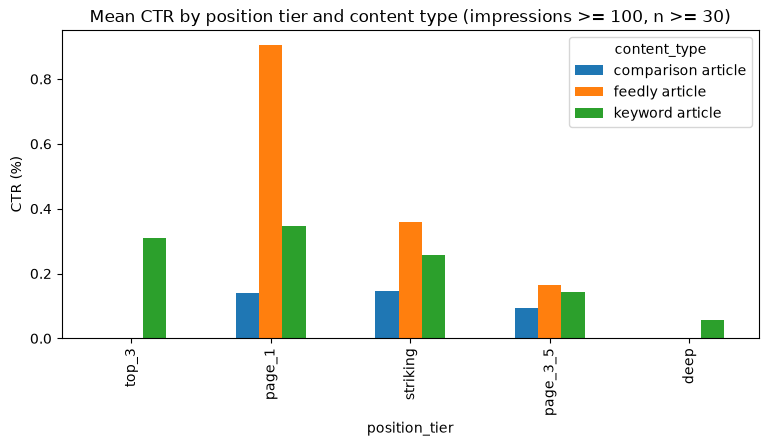

In [8]:
# Your discovery here
# Question picked: in Discovery B, which content_type has the worst CTR *at the same position tier*?
# Same volume floor as Discovery B (impressions_90d >= 100) so CTR isn't driven by 1-2 clicks.
# ctr is a x100 percentage (0.35 = 0.35%). Cells with fewer than 30 pages are hidden as too thin to read.
MIN_PAGES = 30
visible = df[df["impressions_90d"] >= 100]
tier_order = ["top_3", "page_1", "striking", "page_3_5", "deep"]

mean_ctr = visible.pivot_table(index="position_tier", columns="content_type", values="ctr", aggfunc="mean")
median_ctr = visible.pivot_table(index="position_tier", columns="content_type", values="ctr", aggfunc="median")
n_pages = visible.pivot_table(index="position_tier", columns="content_type", values="ctr", aggfunc="size")

mean_ctr = mean_ctr.where(n_pages >= MIN_PAGES).reindex(tier_order)
median_ctr = median_ctr.where(n_pages >= MIN_PAGES).reindex(tier_order)
print("Pages per cell (impressions_90d >= 100):")
print(n_pages.reindex(tier_order).fillna(0).astype(int).to_string())
print()
print("Mean CTR (%) by position tier x content type (cells with <30 pages hidden):")
print(mean_ctr.round(3).to_string())
print()
print("Median CTR (%):")
print(median_ctr.round(3).to_string())
print()

worst = mean_ctr.idxmin(axis=1).dropna()
print("Worst content_type per tier (by mean CTR):")
print(worst.to_string())

ax = mean_ctr.dropna(how="all").plot(kind="bar", title="Mean CTR by position tier and content type (impressions >= 100, n >= 30)", ylabel="CTR (%)")
ax.figure.set_size_inches(9, 4);

# Quick side check (option 1): does dropping zero-impression pages change Discovery A?
pos = df[df["impressions_90d"] > 0]
print()
print(f"Discovery A redo, impressions_90d > 0 ({len(pos):,} pages): "
      f"Pearson {pos['search_volume'].corr(pos['impressions_90d']):.3f}, "
      f"Spearman {pos['search_volume'].corr(pos['impressions_90d'], method='spearman'):.3f}")


### My observation (observed / directional)

**Question:** in Discovery B, which `content_type` has the worst CTR *at the same position tier*?

- **Comparison articles have the lowest CTR in every tier where there are enough of them to read** (`page_1`, `striking`, `page_3_5`, each with 63-226 pages above the 100-impression floor). On `page_1` their mean CTR is about **0.14%**, against about **0.35%** for keyword articles and about **0.90%** for feedly articles. Their *median* CTR is **0** in every tier: most comparison pages with 100+ impressions got no clicks at all in 90 days.
- Keyword articles show up as "worst" in `top_3` and `deep` only because they are the only type with 30+ pages there, so those rows are not a real comparison.
- Feedly articles look best on `page_1`, but their mean (0.90%) is far above their median (0.32%), so a few high-CTR pages pull that average up.

**Big caveat before reading anything into this:** in this sample, *all* comparison-article pages come from **a single client**. So "comparison articles have low CTR" cannot be separated from "this one client's pages have low CTR" (its niche, its titles/snippets, its SERP features). I'd call it a lead to check on the warehouse data, where more clients may publish comparison content, not a finding about content type.

**Side check (option 1):** every page in the starter CSV already has `impressions_90d > 0`, so redoing Discovery A on that subset gives the same near-zero correlation (Pearson 0.001; rank/Spearman -0.03). Search volume still says almost nothing about how often a page is shown.


### Save your work
**Colab:** *File → Save a copy in GitHub* (writes to your own repo — that's your submission) and *File → Save a copy in Drive* (so the session doesn't evaporate).

Next: `02_your_first_readable_model.ipynb` — where the model becomes a rule you can read.